In [1]:
import statistics
import scipy.stats as stats
import logging
from pyts.datasets import load_gunpoint
import matplotlib.pyplot as plt
import math

import torch
import pyro
from pyro.infer import Predictive

from mmbo.mode.timeseries import TSPCA, VarTSPCA
from mmbo.mode.vae import VAE

In [2]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [3]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    while nonimproved < max_nonimproved:
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            current_loss_std = statistics.stdev(losses[-check_interval:])
            reg = stats.linregress(range(check_interval), losses[-check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            logging.info("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return losses

In [33]:
# Custom time series data

def increase_ts(n: int, rate: torch.Tensor, period: torch.Tensor, amp: torch.Tensor, phase: torch.Tensor, noise: torch.Tensor):
    X = torch.linspace(0, 1, steps=n)
    y = X.pow(rate.unsqueeze(-1)) + amp.unsqueeze(-1) * torch.cos(period.unsqueeze(-1) * X + phase.unsqueeze(-1))
    y = y + torch.randn_like(y) * noise.unsqueeze(-1)
    return y

def data(res: int, n: int, p: int = 1):
    rate = torch.randn(n).exp().unsqueeze(-1) * (1 + torch.linspace(-2.0, 2.0, p)/10)
    period = (2 * torch.pi * (1 + 3 * torch.rand(n))).unsqueeze(-1) * (1 + torch.linspace(-2.0, 2.0, p)/10)
    amp = torch.rand(n).unsqueeze(-1) * (1 + torch.linspace(-2.0, 2.0, p)/10)
    phase = (2 * torch.pi * torch.rand(n)).unsqueeze(-1) * (1 + torch.linspace(-2.0, 2.0, p)/10)
    noise = (0.1 * torch.randn(n)).unsqueeze(-1) * (1 + torch.linspace(-2.0, 2.0, p)/10)
    return increase_ts(n = res, rate = rate, period = period, amp = amp, phase = phase, noise = noise)

n_train = 2000
n_test = 100
res = 200
p = 5

X_train = data(res, n_train, p)
X_test = data(res, n_test, p)

In [34]:
X_train.shape

torch.Size([2000, 5, 200])

In [6]:
# # Get data
# X_train, X_test, _, _ = load_gunpoint(return_X_y = True)
# X_train = torch.as_tensor(X_train, dtype=torch.float).unsqueeze(-2)
# X_test = torch.as_tensor(X_test, dtype=torch.float).unsqueeze(-2)

In [35]:
p = TSPCA(X_train, n_components = 0.95)

print(f"{p._n_components} components")


18 components


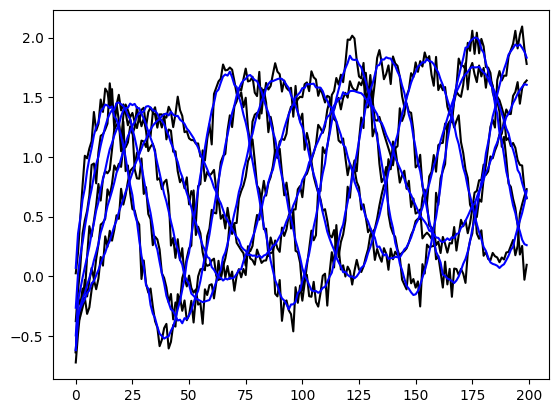

In [39]:
X_test_pred = p.decode(p.encode(X_test))

series = 4

plt.plot(X_test[series,...].mT, color="black")
plt.plot(X_test_pred[series,...].mT, color="blue")
#plt.plot(p.mean_.mT, color="red")

In [14]:
p._pca_init.explained_variance_ratio_.sum()

tensor(0.9835)

In [5]:
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
vae = VAE(data_dim = res, z_dim = 10, hidden_dim = 200, depth = 2)
svi = pyro.infer.SVI(vae.model, vae.guide, adam, elbo)

In [6]:
with param_store.scope() as vae_params:
    losses = do_svi(svi, X_train, check_interval = 1000)

In [ ]:
plt.plot(losses)


In [ ]:
print(vae.error_scale_loc)
print(vae.error_scale_scale)
pyro.distributions.LogNormal(vae.error_scale_loc, vae.error_scale_scale).sample((1000,)).mean(dim=0)


In [ ]:
len(plt.plot(vae.generate(50).detach().mT))


In [ ]:
vae.train(False)

In [ ]:
plt.hist((vae.encode(X_test)[0]).detach().reshape(-1))
plt.hist((vae.encode(X_test)[1]).detach().reshape(-1))

In [23]:
X_plot = X_test

posterior_samples = vae.decode(Predictive(lambda: vae.model(X_plot), guide = lambda: vae.guide(X_plot), num_samples = 1000).get_samples()["latent"])

In [ ]:
series = 43
_ = plt.plot(posterior_samples[:,series,:].detach().mT)
_ = plt.plot(X_plot[series,:], color="black")


In [ ]:
posterior_samples.std(dim=0).mean(dim=-1)